# Tim 07 – Analiza podataka (2. termin)
**Segmentacija krvnih žila mrežnice** – skupovi FIVES i CHASE_DB1.

Bilježnica poziva funkcije iz `src/` i prikazuje sve brojke i grafove iz izvještaja `07_izvjestaj_1.pdf`.

**Pokretanje:** vidi `README.md` (preuzimanje podataka u `../data`, zatim `python src/prepare_data.py`).
Prvo izvođenje `compute_image_stats` traje ~4 min (8 jezgri); rezultat se sprema u cache.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd
from IPython.display import Image, display
import data_analysis as da
from config import FIG_DIR, METRICS_DIR
pd.set_option("display.precision", 3)

## 1. Popis slika i podjela na train / val / test

In [2]:
split_all = da.load_split()
print("Ukupno:", len(split_all))
print("Izbačene (prazna maska):", split_all.loc[split_all.split == "excluded", "id"].tolist())
split = split_all[split_all.split != "excluded"].reset_index(drop=True)
pd.crosstab([split.dataset, split.disease], split.split, margins=True)[["train", "val", "test", "All"]]

Ukupno: 828
Izbačene (prazna maska): ['FIVES_train_447_G', 'FIVES_train_448_G']


split               train  val  test  All
dataset   disease                        
CHASE_DB1 normalno     20    4     4   28
FIVES     AMD         139   29    32  200
          DR          140   30    30  200
          glaukom     140   29    29  198
          normalno    140   30    30  200
All                   579  122   125  826

In [3]:
# provjera curenja: niti jedna grupa (dijete u CHASE-u) nije u više podskupova
assert split.groupby("group").split.nunique().max() == 1
split[split.dataset == "CHASE_DB1"].groupby("split").group.unique()

split
test                          [CHASE_subj07, CHASE_subj08]
train    [CHASE_subj01, CHASE_subj02, CHASE_subj03, CHA...
val                           [CHASE_subj04, CHASE_subj10]
Name: group, dtype: object

## 2. Statistike po slici

In [4]:
stats, extra = da.compute_image_stats(split)
stats.groupby("dataset")[["height", "width", "mask_unique_values"]].agg(["min", "max"])

height       width       mask_unique_values    
             min   max   min   max                min max
dataset                                                  
CHASE_DB1    960   960   999   999                  2   2
FIVES       2048  2048  2048  2048                  2   2

In [5]:
print("Slika i maska iste veličine:", stats.img_mask_same_size.all())
print("Udio piksela maske izvan vidnog polja (max):", stats.vessel_outside_fov.max().round(4))
da.summary_table(stats).round(3)

Slika i maska iste veličine: True
Udio piksela maske izvan vidnog polja (max): 0.0182


,skup,znacajka,prosjek,medijan,min,max,std
0,FIVES,Udio zila u FOV,0.096,0.102,0.009,0.145,0.024
1,FIVES,Sr. sirina zile [px],13.242,13.251,8.516,19.768,1.391
2,FIVES,Udio tankih zila,0.284,0.281,0.077,0.528,0.071
3,FIVES,Kontrast zila (G),0.121,0.122,-0.066,0.278,0.045
4,FIVES,Ostrina (var. Laplace),13.622,12.555,1.135,40.293,6.331
5,FIVES,Br. komponenti,4.593,4.000,1.000,41.000,3.271
6,CHASE_DB1,Udio zila u FOV,0.100,0.104,0.072,0.122,0.014
7,CHASE_DB1,Sr. sirina zile [px],6.066,6.007,4.923,7.309,0.553
8,CHASE_DB1,Udio tankih zila,0.302,0.305,0.132,0.445,0.077
9,CHASE_DB1,Kontrast zila (G),0.135,0.142,0.048,0.182,0.033


In [6]:
stats.groupby(["dataset", "disease"])[["vessel_frac_fov", "thin_frac", "width_mean_px", "vessel_contrast", "sharpness"]].mean()

vessel_frac_fov  thin_frac  width_mean_px  \
dataset   disease                                               
CHASE_DB1 normalno            0.100      0.302          6.066   
FIVES     AMD                 0.094      0.308         12.823   
          DR                  0.089      0.266         13.792   
          glaukom             0.085      0.286         12.874   
          normalno            0.113      0.274         13.475   

                    vessel_contrast  sharpness  
dataset   disease                               
CHASE_DB1 normalno            0.135     11.736  
FIVES     AMD                 0.112     18.724  
          DR                  0.107     13.968  
          glaukom             0.126      8.653  
          normalno            0.140     13.092

## 3. Primjeri i raspodjela oznaka

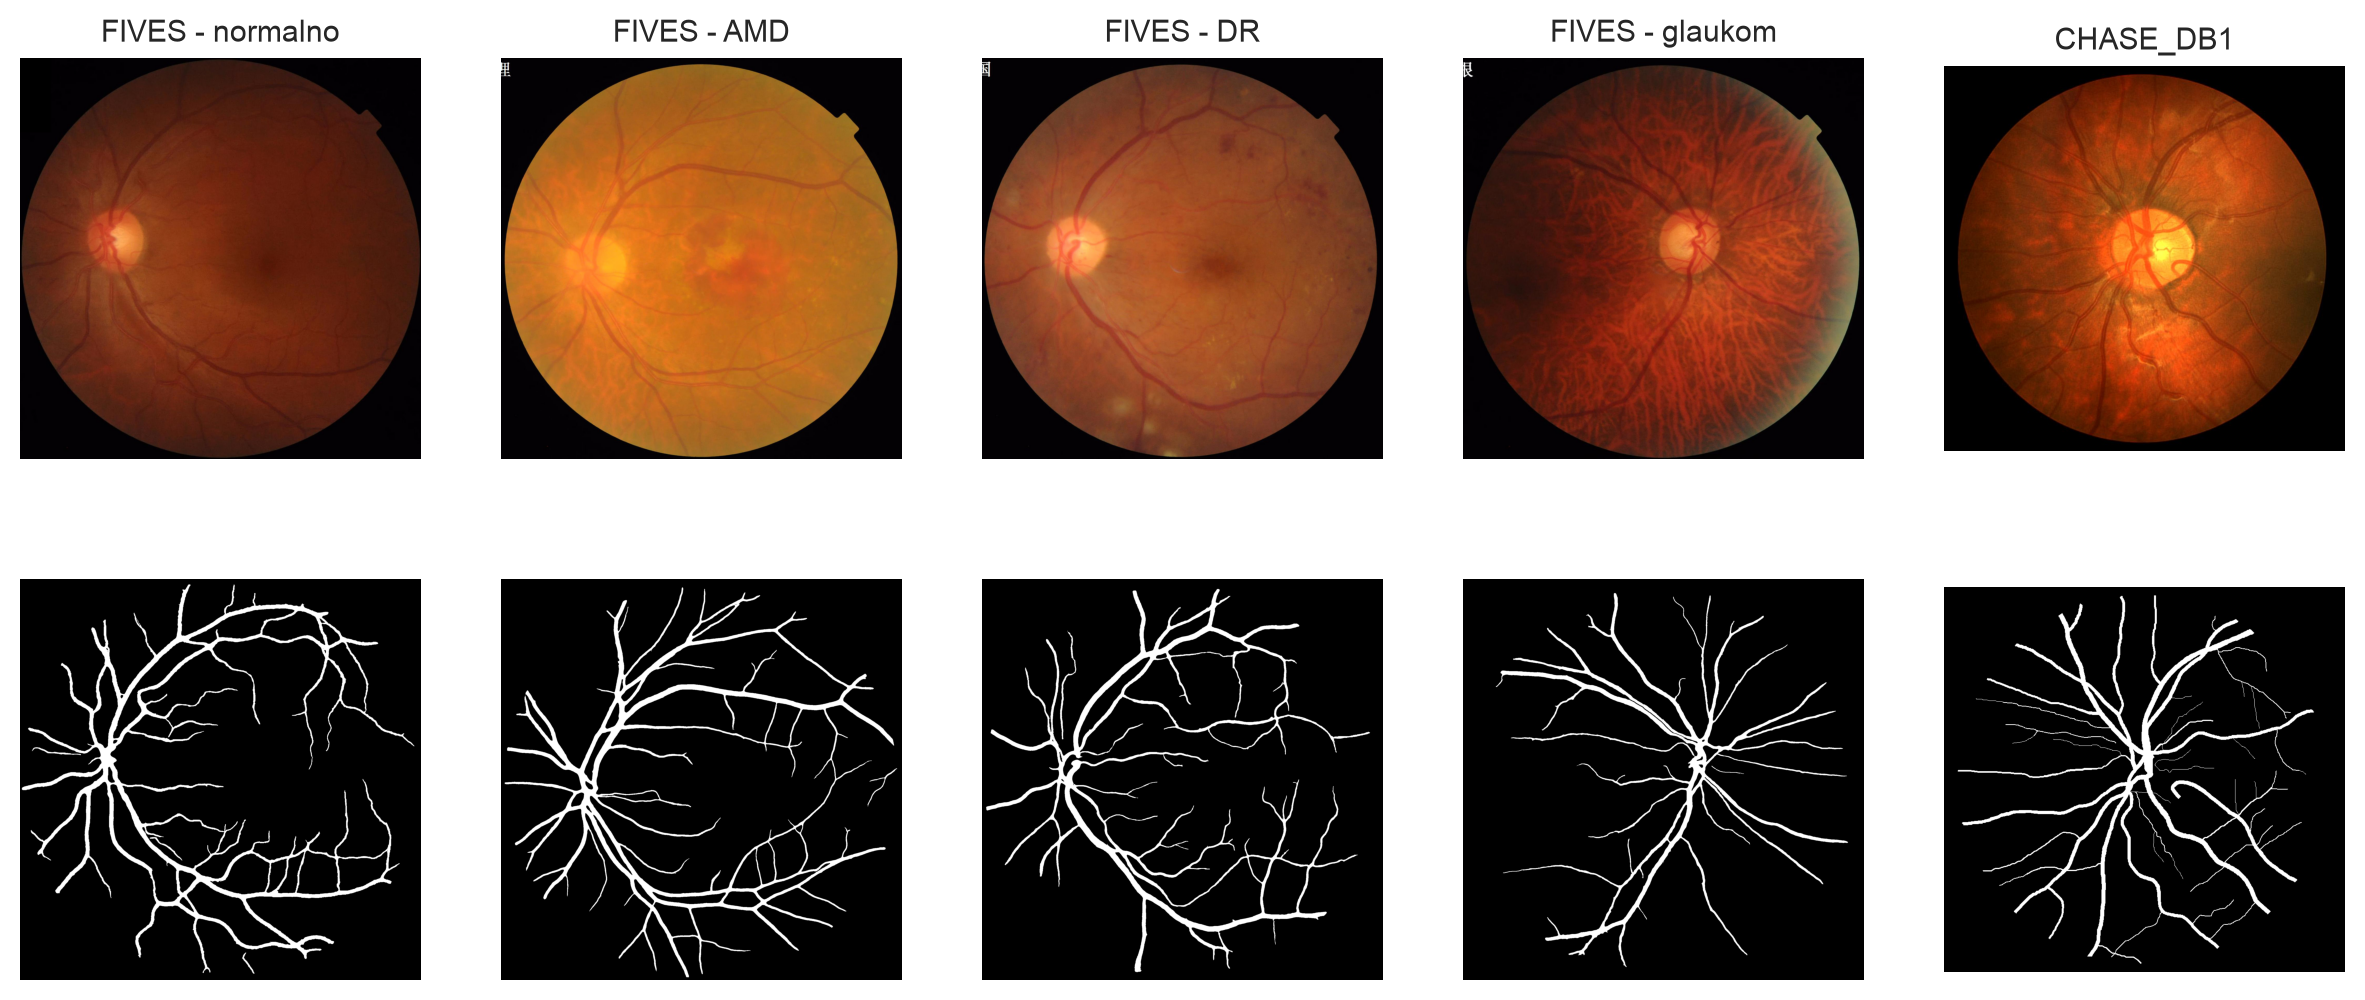

In [7]:
da.plot_examples(split); display(Image(FIG_DIR / "fig_examples.png", width=900))

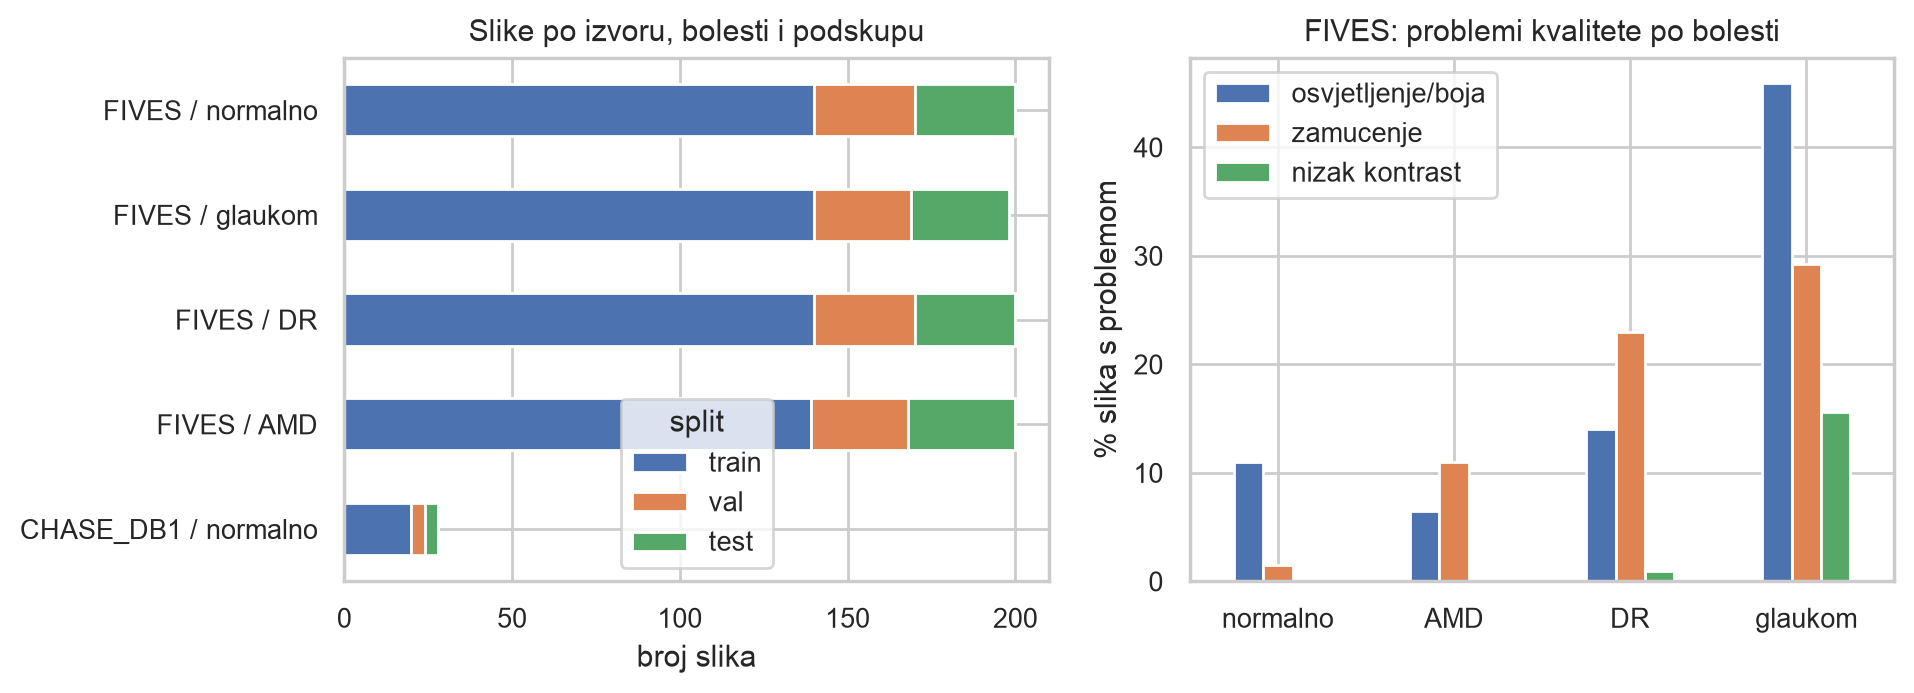

q_illumination    0.193
q_blur            0.162
q_contrast        0.041
Name: udio s problemom, dtype: float64

In [8]:
da.plot_distribution(split); display(Image(FIG_DIR / "fig_distribution.png", width=900))
fives = split[split.dataset == "FIVES"]
(1 - fives[["q_illumination", "q_blur", "q_contrast"]]).mean().rename("udio s problemom")

## 4. Svojstva žila: udio, širina, kontrast

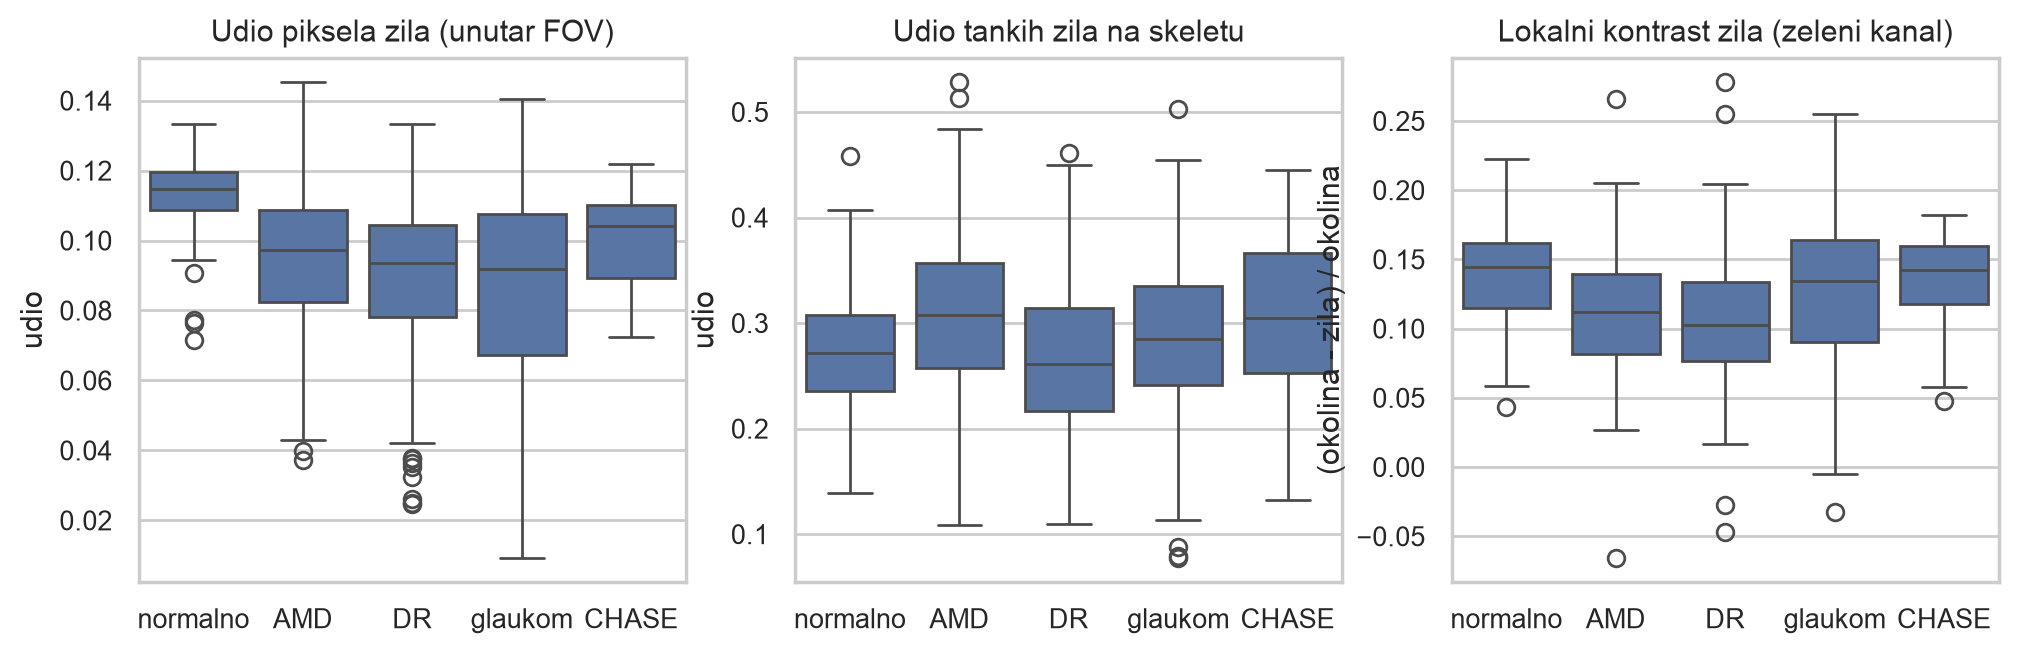

In [9]:
da.plot_vessel_stats(stats); display(Image(FIG_DIR / "fig_vessel_stats.png", width=900))

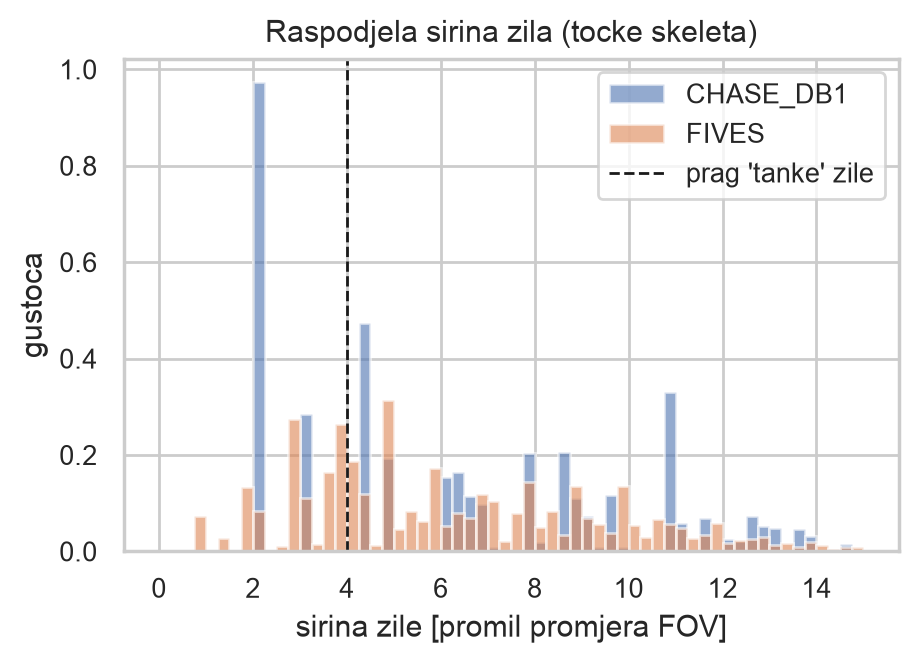

In [10]:
da.plot_width_hist(stats, extra); display(Image(FIG_DIR / "fig_width_hist.png", width=500))

## 5. RGB kanali i predobrada (motivacija za eksperiment 2)

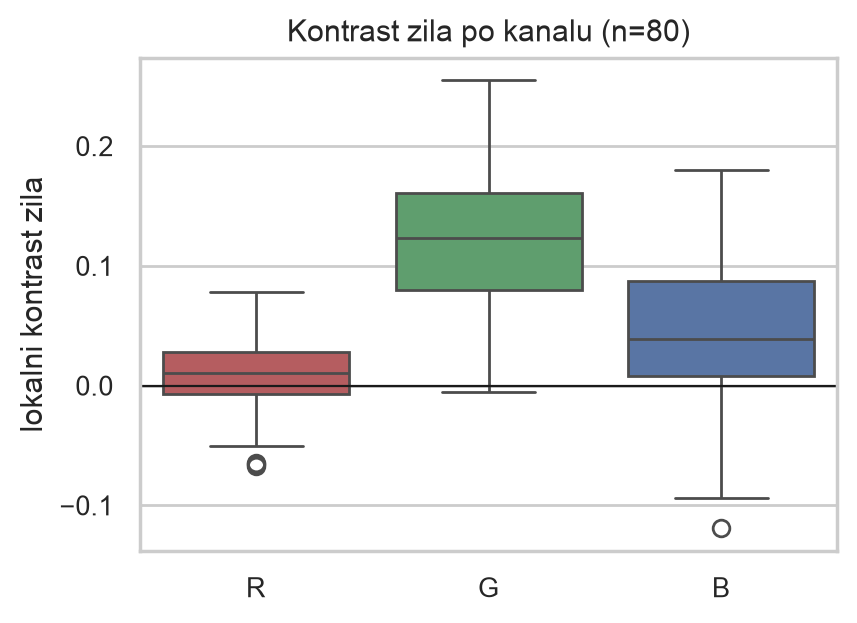

,R,G,B
count,80.000,80.000,80.000
mean,0.008,0.123,0.044
std,0.029,0.050,0.058
min,-0.067,-0.005,-0.119
25%,-0.007,0.080,0.008
50%,0.010,0.124,0.039
75%,0.028,0.161,0.087
max,0.078,0.255,0.180


In [11]:
cc = da.plot_channel_contrast(split); display(Image(FIG_DIR / "fig_channel_contrast.png", width=450)); cc.describe()

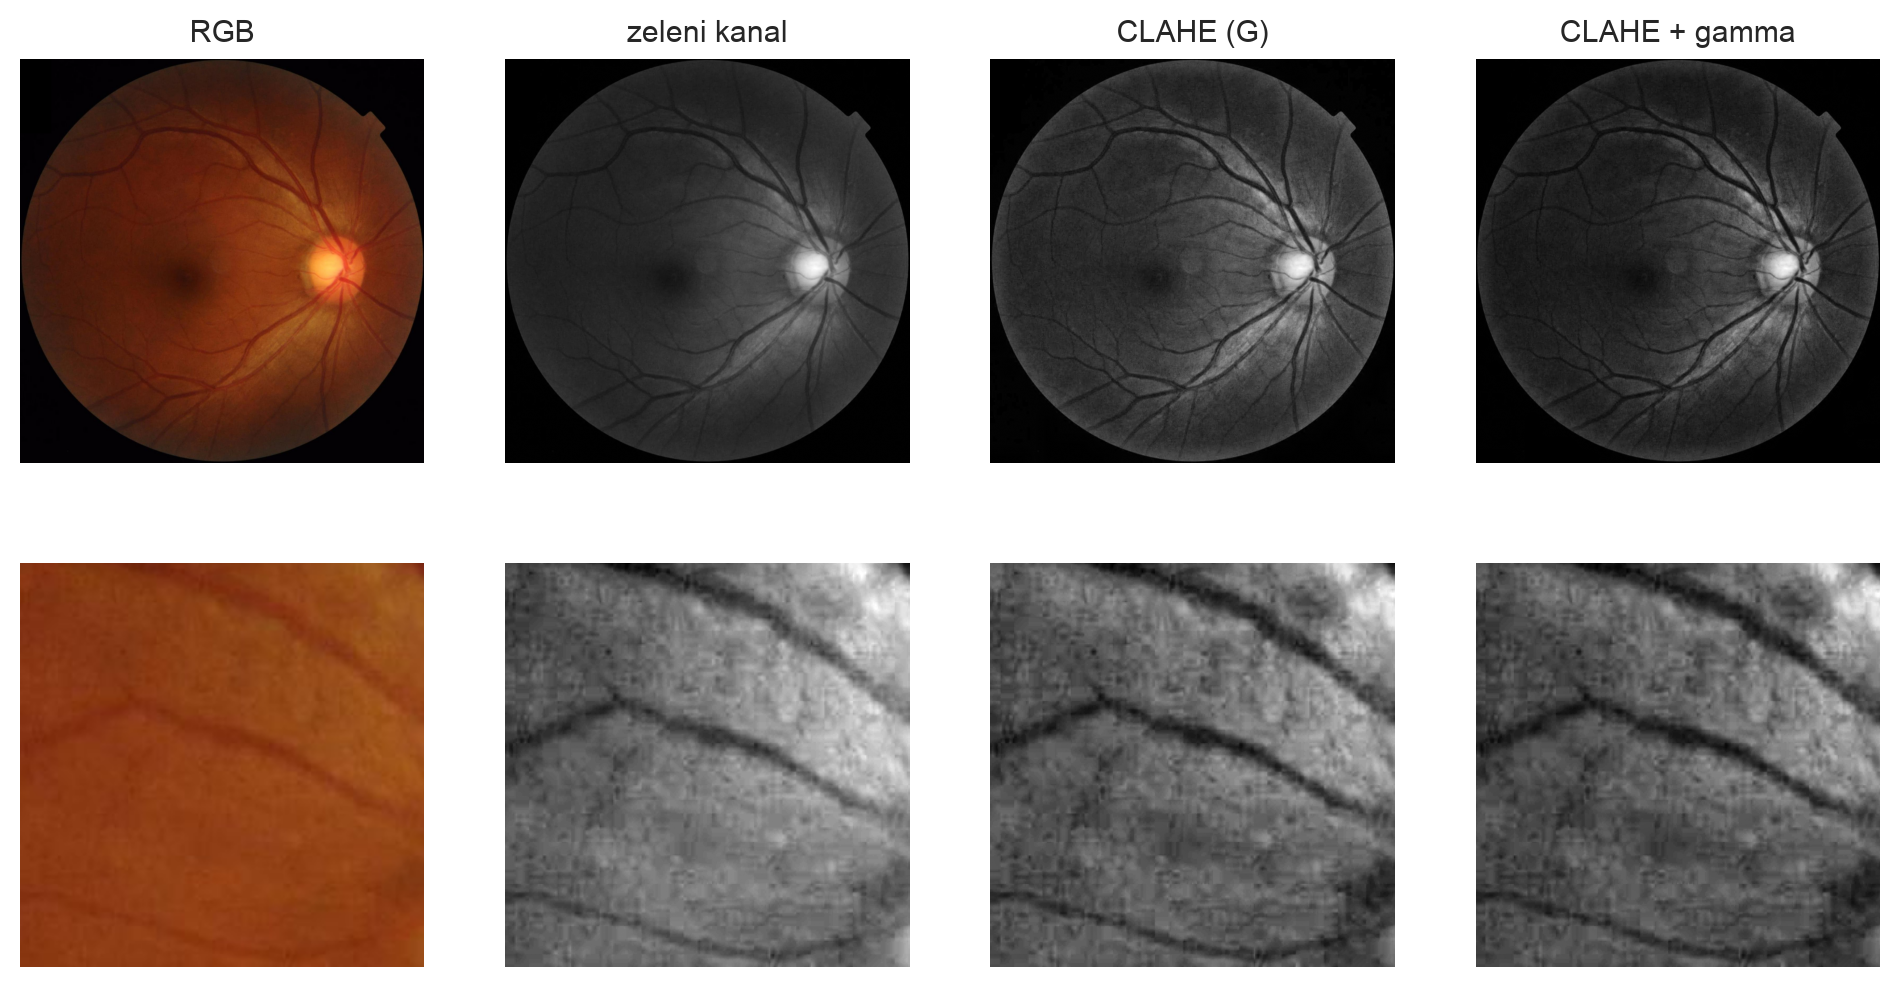

In [12]:
da.plot_preprocessing(split, "FIVES_train_455_N"); display(Image(FIG_DIR / "fig_preprocessing.png", width=900))

## 6. Patchevi 768×768 i neuravnoteženost klasa

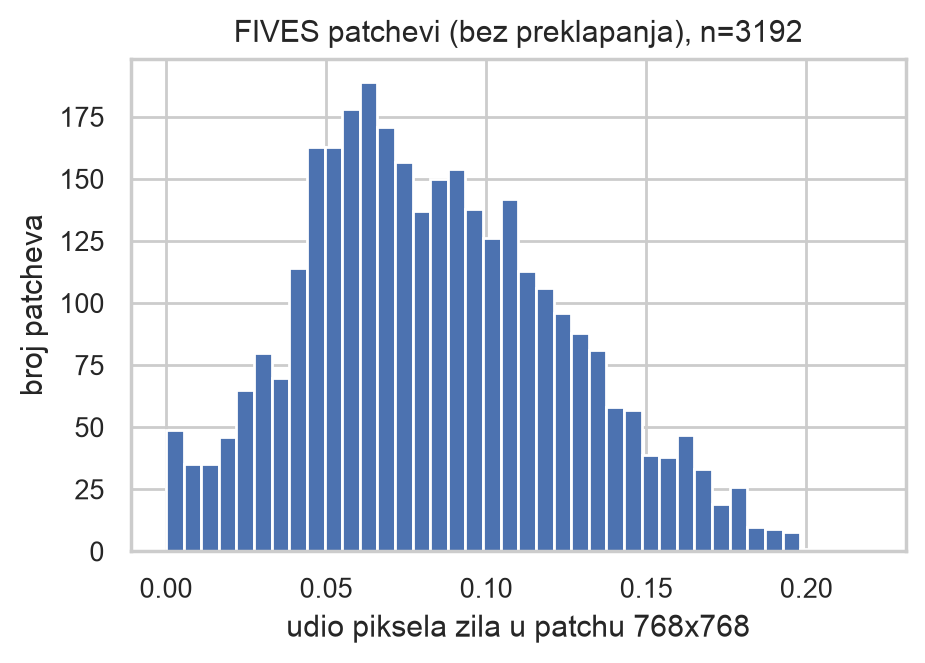

Patcheva: 3192, bez ijednog piksela žile: 0.7%, s <1% žila: 2.4%
Prosječan omjer pozadina:žila (cijela slika) = 12.6 : 1


In [13]:
fr = da.plot_patches(stats, extra); display(Image(FIG_DIR / "fig_patches.png", width=500))
print(f"Patcheva: {len(fr)}, bez ijednog piksela žile: {(fr == 0).mean():.1%}, s <1% žila: {(fr < 0.01).mean():.1%}")
print(f"Prosječan omjer pozadina:žila (cijela slika) = {(1 - stats.vessel_frac_img.mean()) / stats.vessel_frac_img.mean():.1f} : 1")

## 7. Odnosi između značajki

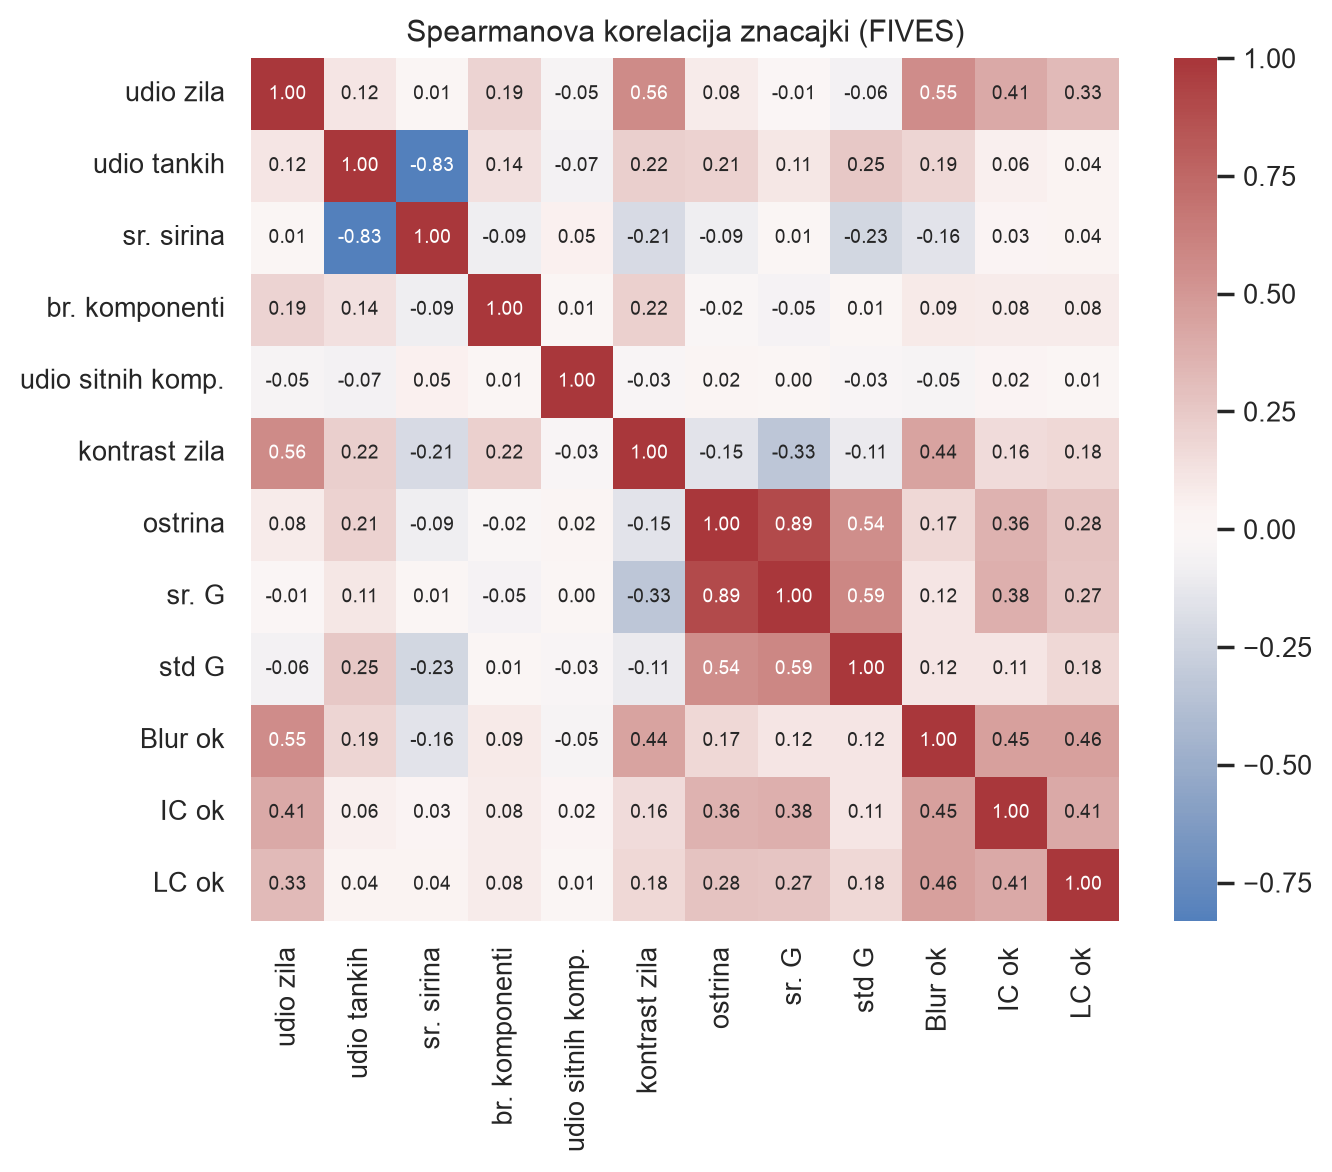

In [14]:
corr = da.plot_correlation(stats); display(Image(FIG_DIR / "fig_correlation.png", width=600))

In [15]:
# ocjena kvalitete iz FIVES-a vs. izmjerena oštrina
fives = stats[stats.dataset == "FIVES"]
fives.groupby("q_blur")[["sharpness", "vessel_contrast", "vessel_frac_fov"]].median()

,sharpness,vessel_contrast,vessel_frac_fov
q_blur,,,
0.0,10.440,0.072,0.061
1.0,12.913,0.132,0.106


## 8. Potencijalni problemi: duplikati, sumnjive maske, curenje

FIVES ne daje ID pacijenta. Uspoređujemo smanjene maske (64×64) svih parova slika (IoU).
Nesrodne mrežnice imaju IoU ~0.1–0.35, pa par s IoU > 0.5 smatramo istim okom. `prepare_data.py` takve slike stavlja u istu grupu (isti podskup).

In [16]:
dups, iou = da.find_near_duplicates(stats, extra)
v = iou[np.triu_indices(len(iou), 1)]
print("Percentili IoU svih parova (50, 99, 99.9, 99.99):", np.percentile(v, [50, 99, 99.9, 99.99]).round(3))
print("Parova s IoU > 0.5:", len(dups), "| od toga u različitim podskupovima:", (dups.split_a != dups.split_b).sum())
dups

Percentili IoU svih parova (50, 99, 99.9, 99.99): [0.201 0.307 0.334 0.364]
Parova s IoU > 0.5: 22 | od toga u različitim podskupovima: 0


,id_a,id_b,iou,split_a,split_b
18,FIVES_test_022_A,FIVES_test_023_A,1.000,test,test
6,FIVES_train_174_D,FIVES_test_054_D,0.998,train,train
19,FIVES_test_032_A,FIVES_test_048_A,0.993,train,train
2,FIVES_train_118_A,FIVES_train_034_A,0.966,train,train
3,FIVES_train_121_A,FIVES_train_061_A,0.965,test,test
16,FIVES_train_053_A,FIVES_train_097_A,0.951,test,test
5,FIVES_train_134_A,FIVES_train_055_A,0.940,test,test
4,FIVES_train_132_A,FIVES_train_039_A,0.916,train,train
7,FIVES_train_238_D,FIVES_train_239_D,0.714,train,train
15,FIVES_train_472_N,FIVES_test_118_G,0.685,train,train


In [17]:
# isti par u službenoj FIVES podjeli: koliko 'duplikata' prelazi službeni train/test?
o = split.set_index("id").orig_split
dups.assign(orig_a=dups.id_a.map(o), orig_b=dups.id_b.map(o)).query("orig_a != orig_b")

,id_a,id_b,iou,split_a,split_b,orig_a,orig_b
6,FIVES_train_174_D,FIVES_test_054_D,0.998,train,train,train,test
15,FIVES_train_472_N,FIVES_test_118_G,0.685,train,train,train,test
14,FIVES_train_466_N,FIVES_test_106_G,0.675,train,train,train,test
0,FIVES_train_112_A,FIVES_test_033_A,0.562,train,train,train,test
1,FIVES_train_112_A,FIVES_test_003_A,0.542,train,train,train,test


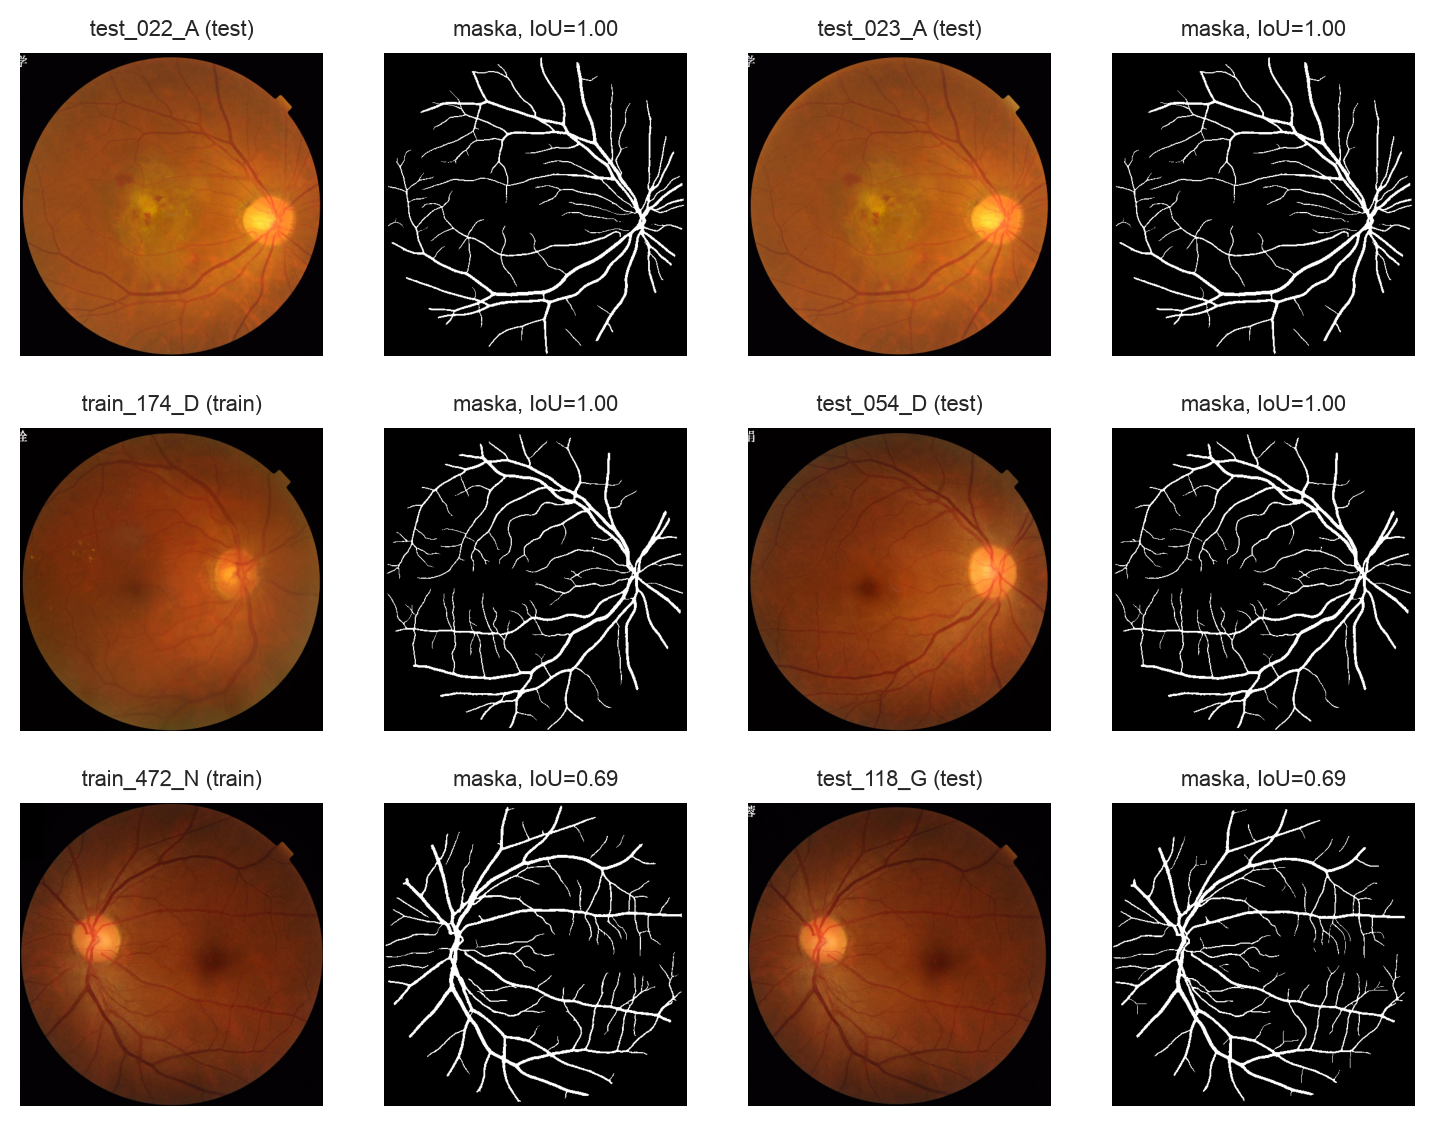

In [18]:
da.plot_duplicates(split, [("FIVES_test_022_A", "FIVES_test_023_A", 1.0), ("FIVES_train_174_D", "FIVES_test_054_D", 0.998), ("FIVES_train_472_N", "FIVES_test_118_G", 0.685)])
display(Image(FIG_DIR / "fig_duplicates.png", width=700))

In [19]:
print("Udio FIVES slika s tekstom/vodenim žigom u gornjem lijevom kutu:", stats[stats.dataset == "FIVES"].corner_text.mean().round(3))

Udio FIVES slika s tekstom/vodenim žigom u gornjem lijevom kutu: 0.717


In [20]:
# maske s neobično malim udjelom žila (djelomična anotacija na lošim slikama)
stats.nsmallest(8, "vessel_frac_fov")[["id", "disease", "q_blur", "q_contrast", "vessel_frac_fov", "sharpness"]]

,id,disease,q_blur,q_contrast,vessel_frac_fov,sharpness
239,FIVES_train_316_G,glaukom,0.0,0.0,0.009,13.132
622,FIVES_test_122_G,glaukom,0.0,0.0,0.010,11.087
337,FIVES_train_404_G,glaukom,0.0,0.0,0.014,6.160
256,FIVES_train_331_G,glaukom,0.0,0.0,0.018,5.897
623,FIVES_test_123_G,glaukom,0.0,0.0,0.022,6.605
289,FIVES_train_361_G,glaukom,0.0,0.0,0.023,8.938
334,FIVES_train_401_G,glaukom,0.0,0.0,0.024,13.895
172,FIVES_train_256_D,DR,0.0,1.0,0.025,5.004


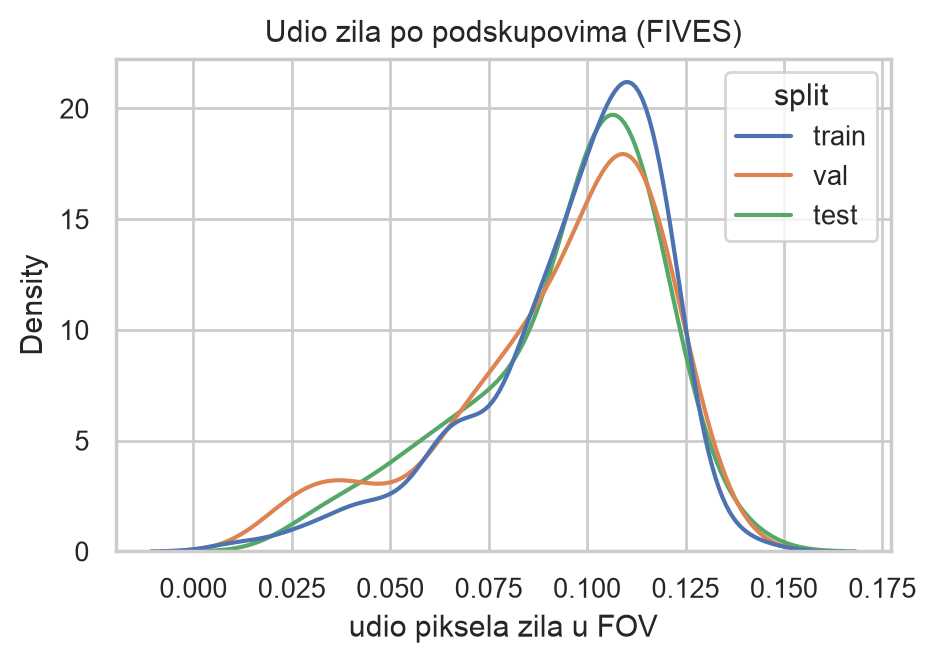

In [21]:
da.plot_split_check(stats); display(Image(FIG_DIR / "fig_split_check.png", width=500))

## 9. "Laki" i "teški" primjeri

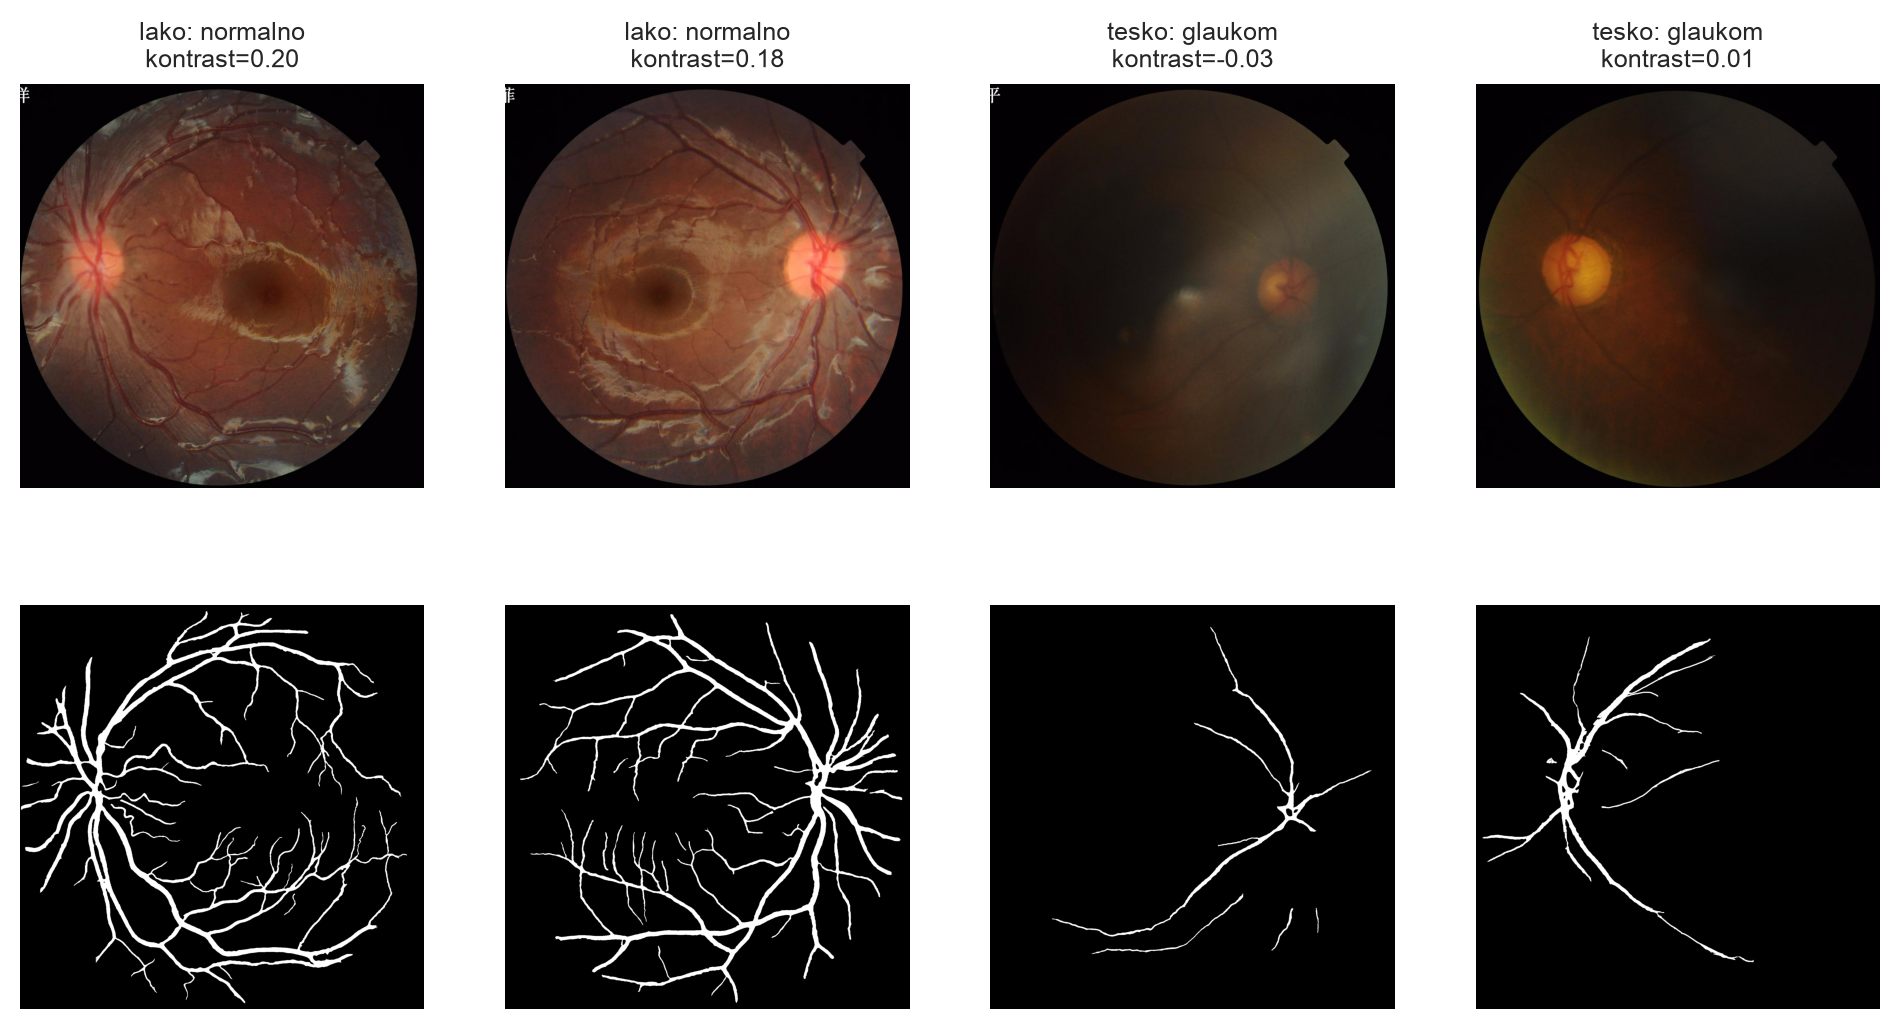

,id,disease,vessel_contrast,sharpness,thin_frac,q_blur
683,FIVES_test_178_N,normalno,0.195,24.430,0.263,1.0
678,FIVES_test_173_N,normalno,0.183,18.221,0.234,1.0
256,FIVES_train_331_G,glaukom,-0.033,5.897,0.435,0.0
310,FIVES_train_380_G,glaukom,0.008,4.252,0.395,0.0


In [22]:
easy, hard = da.pick_easy_hard(stats)
da.plot_easy_hard(easy, hard); display(Image(FIG_DIR / "fig_easy_hard.png", width=900))
pd.concat([easy, hard])[["id", "disease", "vessel_contrast", "sharpness", "thin_frac", "q_blur"]]